<a href="https://colab.research.google.com/github/atman500/atman500/blob/main/Simple_tree_decission.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [35]:
import numpy as np
import pandas as pd
from google.colab import files

In [36]:
upload=files.upload()

Saving tree_decission.csv to tree_decission (1).csv


In [38]:
df=pd.read_csv("tree_decission.csv",sep=";")
print(df.head())

  Observation   Number of Late Payments  Credit Risk Level  Class
0           A                         1                  1     -1
1           B                         2                  1     -1
2           C                         1                  2     -1
3           D                         4                  4      1
4           E                         5                  4      1


In [39]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 4 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Observation               6 non-null      object
 1    Number of Late Payments  6 non-null      int64 
 2   Credit Risk Level         6 non-null      int64 
 3   Class                     6 non-null      int64 
dtypes: int64(3), object(1)
memory usage: 324.0+ bytes


In [40]:
df.describe()

,Number of Late Payments,Credit Risk Level,Class
count,6.000000,6.000000,6.000000
mean,2.833333,2.833333,0.000000
std,1.722401,1.722401,1.095445
min,1.000000,1.000000,-1.000000
25%,1.250000,1.250000,-1.000000
50%,3.000000,3.000000,0.000000
75%,4.000000,4.000000,1.000000
max,5.000000,5.000000,1.000000


Apply a Tree  Decission model

In [41]:
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree

In [43]:
model = DecisionTreeClassifier(
    criterion='gini',
    random_state=42
)

# Accessing the columns correctly from the DataFrame df
# Note the leading space in ' Number of Late Payments' based on df.info()
X = df[[' Number of Late Payments']]
y = df['Class']

model.fit(X, y)

DecisionTreeClassifier(random_state=42)

Also we can Develope the next codink to get the same results




Root Gini Impurity = 0.5000

Gini Evaluation for X1:
 Threshold Left observations Right observations  Gini Left  Gini Right  Weighted Gini  Gini Gain
       1.5            [A, C]       [B, D, E, F]       0.00       0.375           0.25       0.25
       3.0         [A, B, C]          [D, E, F]       0.00       0.000           0.00       0.50
       4.5   [A, B, C, D, F]                [E]       0.48       0.000           0.40       0.10

Optimal threshold for X1 = 3.0
Minimum weighted Gini = 0.0000
Maximum Gini Gain = 0.5000


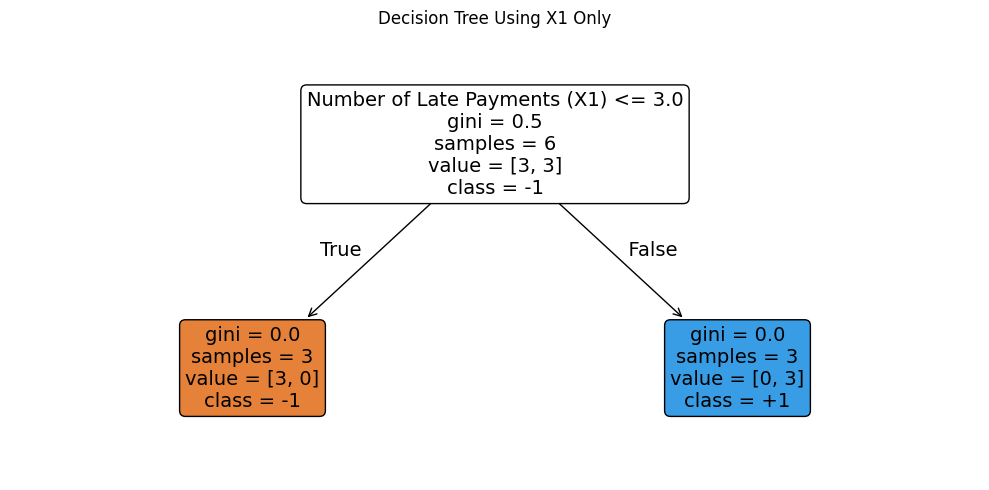

In [53]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree

# 1. Create the dataset
df = pd.DataFrame({
    'Observation': ['A', 'B', 'C', 'D', 'E', 'F'],
    'X1': [1, 2, 1, 4, 5, 4],
    'X2': [1, 1, 2, 4, 4, 5],
    'Class': [-1, -1, -1, 1, 1, 1]
})

# 2. Define the Gini impurity function
def gini(y):
    if len(y) == 0:
        return 0.0
    proportions = y.value_counts(normalize=True)
    return 1 - (proportions ** 2).sum()

# 3. Calculate the root Gini impurity
root_gini = gini(df['Class'])
print(f"Root Gini Impurity = {root_gini:.4f}")

# 4. Evaluate the candidate thresholds for X1
thresholds = [1.5, 3.0, 4.5]
results = []

for t in thresholds:
    left = df[df['X1'] <= t]
    right = df[df['X1'] > t]

    g_left = gini(left['Class'])
    g_right = gini(right['Class'])

    weighted_gini = (
        len(left) / len(df) * g_left
        + len(right) / len(df) * g_right
    )

    gain = root_gini - weighted_gini

    results.append({
        'Threshold': t,
        'Left observations': list(left['Observation']),
        'Right observations': list(right['Observation']),
        'Gini Left': g_left,
        'Gini Right': g_right,
        'Weighted Gini': weighted_gini,
        'Gini Gain': gain
    })

results_df = pd.DataFrame(results)

print("\nGini Evaluation for X1:")
print(results_df.to_string(index=False))

# 5. Select the threshold with minimum weighted Gini
best = results_df.loc[results_df['Weighted Gini'].idxmin()]
best_threshold = best['Threshold']

print(f"\nOptimal threshold for X1 = {best_threshold}")
print(f"Minimum weighted Gini = {best['Weighted Gini']:.4f}")
print(f"Maximum Gini Gain = {best['Gini Gain']:.4f}")

# 6. Train a Decision Tree using X1 only
X = df[['X1']]
y = df['Class']

model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=1,
    random_state=42
)

model.fit(X, y)

# 7. Plot the Decision Tree
plt.figure(figsize=(10, 5))

plot_tree(
    model,
    feature_names=['Number of Late Payments (X1)'],
    class_names=['-1', '+1'],
    filled=True,
    rounded=True,
    impurity=True,
    proportion=False
)

plt.title("Decision Tree Using X1 Only")
plt.tight_layout()
plt.show()


Rem: Gini Gain =  Gini_root -  Gini Split .......Gini Gain = 0.5 -0 = 0.5

Second variabale:

Root Gini Impurity = 0.5000

Gini Evaluation for X2:
 Threshold Left observations Right observations  Gini Left  Gini Right  Weighted Gini  Gini Gain
       1.5            [A, B]       [C, D, E, F]       0.00       0.375           0.25       0.25
       3.0         [A, B, C]          [D, E, F]       0.00       0.000           0.00       0.50
       4.5   [A, B, C, D, E]                [F]       0.48       0.000           0.40       0.10

Optimal threshold for X2 = 3.0
Minimum weighted Gini = 0.0000
Maximum Gini Gain = 0.5000


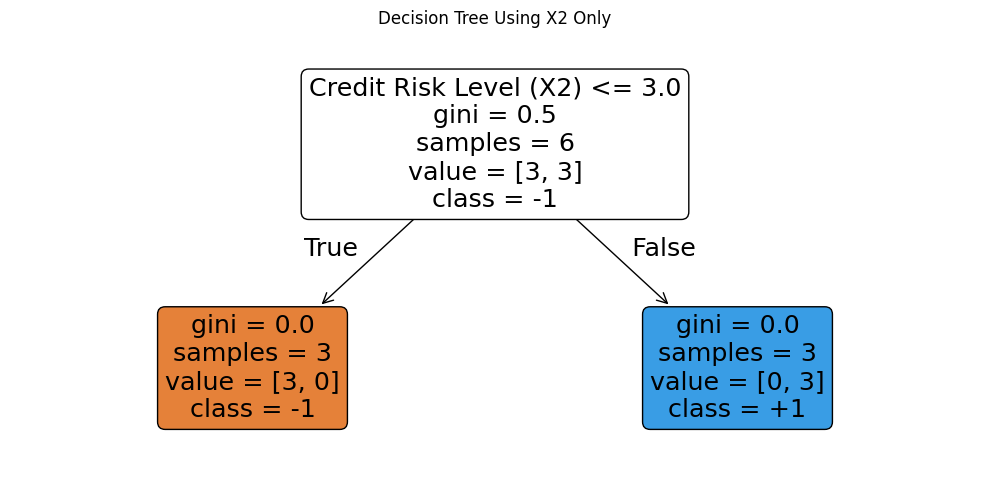

In [54]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree

# 1. Create the dataset
df = pd.DataFrame({
    'Observation': ['A', 'B', 'C', 'D', 'E', 'F'],
    'X1': [1, 2, 1, 4, 5, 4],
    'X2': [1, 1, 2, 4, 4, 5],
    'Class': [-1, -1, -1, 1, 1, 1]
})

# 2. Define the Gini impurity function
def gini(y):
    if len(y) == 0:
        return 0.0
    proportions = y.value_counts(normalize=True)
    return 1 - (proportions ** 2).sum()

# 3. Calculate the root Gini impurity
root_gini = gini(df['Class'])
print(f"Root Gini Impurity = {root_gini:.4f}")

# 4. Evaluate all candidate thresholds for X2
thresholds = [1.5, 3.0, 4.5]
results = []

for t in thresholds:
    left = df[df['X2'] <= t]
    right = df[df['X2'] > t]

    g_left = gini(left['Class'])
    g_right = gini(right['Class'])

    weighted_gini = (
        len(left) / len(df) * g_left
        + len(right) / len(df) * g_right
    )

    gain = root_gini - weighted_gini

    results.append({
        'Threshold': t,
        'Left observations': list(left['Observation']),
        'Right observations': list(right['Observation']),
        'Gini Left': g_left,
        'Gini Right': g_right,
        'Weighted Gini': weighted_gini,
        'Gini Gain': gain
    })

results_df = pd.DataFrame(results)

print("\nGini Evaluation for X2:")
print(results_df.to_string(index=False))

# 5. Identify the best threshold
best = results_df.loc[results_df['Weighted Gini'].idxmin()]
best_threshold = best['Threshold']

print(f"\nOptimal threshold for X2 = {best_threshold}")
print(f"Minimum weighted Gini = {best['Weighted Gini']:.4f}")
print(f"Maximum Gini Gain = {best['Gini Gain']:.4f}")

# 6. Train a Decision Tree using X2 only
X = df[['X2']]
y = df['Class']

model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=1,
    random_state=42
)

model.fit(X, y)

# 7. Plot the Decision Tree
plt.figure(figsize=(10, 5))

plot_tree(
    model,
    feature_names=['Credit Risk Level (X2)'],
    class_names=['-1', '+1'],
    filled=True,
    rounded=True,
    impurity=True
)

plt.title("Decision Tree Using X2 Only")
plt.tight_layout()
plt.show()
